# FCC-ee single-beam power loss

Supply a longitudinal impedance, choose an FCC-ee operation mode, and calculate single-beam power loss. The supplied IR central-pipe file is an example; every later cell uses the `bihc.Impedance` object `Z`, so you can use another measured or modeled impedance.

Use a Python kernel with this BIHC checkout installed (for example, `pip install -e .` from the repository root).

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
from scipy.constants import c

import bihc
from bihc.fillingschemes import (
    fillingSchemeFCCee_WW,
    fillingSchemeFCCee_ZH,
    fillingSchemeFCCee_ttbar,
)

## Load and inspect an impedance

This example loads the supplied 100 GHz central-pipe data. Replace the next cell with any public-API construction of a `bihc.Impedance` named `Z` to study another component. For this file, the first column is in GHz and there is one header line.

In [2]:
filename = "Z_IRCentralPipe.dat"
path_to_file = "data/"

Z = bihc.Impedance()
Z.getImpedanceFromCST(path_to_file + filename, unit="GHz", skip_header=1)
print(f"Loaded {len(Z.f)} impedance points through {Z.f[-1] / 1e9:.0f} GHz")

Loaded 901 impedance points through 100 GHz


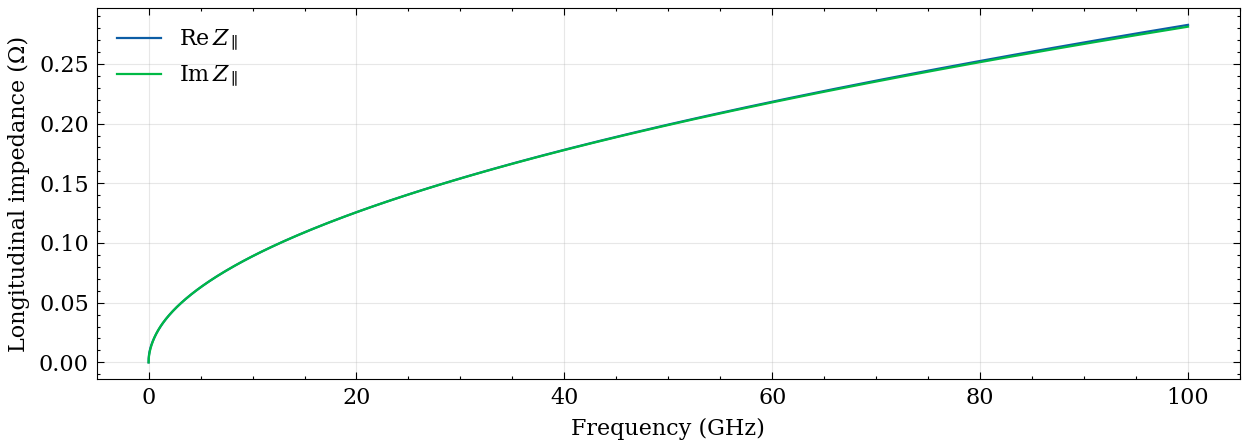

In [3]:
fig, ax = plt.subplots(figsize=(8, 3))
ax.plot(Z.f / 1e9, Z.Zr, label=r"$\mathrm{Re}\,Z_\parallel$")
ax.plot(Z.f / 1e9, Z.Zi, label=r"$\mathrm{Im}\,Z_\parallel$")
ax.set(xlabel="Frequency (GHz)", ylabel="Longitudinal impedance (Ω)")
ax.legend()
ax.grid(alpha=0.3)
plt.show()

## Choose an operation mode

A **train** and a **batch** mean the same bunch group. Several trains/batches form an injection. Filled bunches occupy adjacent slots within each train/batch; the numbers below are *empty* slots in each gap.

| Mode | Injections | Trains/batches per injection | Bunches per train/batch | Gap between trains/batches | Gap between injections |
| --- | ---: | ---: | ---: | ---: | ---: |
| ZH | 2 | 75 | 2 | 19 | 3,764 |
| WW | 8 | 58 | 4 | 16 | 371 |
| ttbar | 2 | 16 | 2 | 151 | 3,763 |

Each wrapper returns 12,120 occupied or empty slots. The nominal slot spacing is 25 ns; BIHC uses the FCC-ee revolution period to construct the beam.

In [4]:
mode = "ZH"  # Choose "ZH", "WW", or "ttbar".
modes = {
    "ZH": {"scheme": fillingSchemeFCCee_ZH, "sigma_z_mm": 5.59, "Np": 1.15e11},
    "WW": {"scheme": fillingSchemeFCCee_WW, "sigma_z_mm": 5.40, "Np": 1.45e11},
    "ttbar": {"scheme": fillingSchemeFCCee_ttbar, "sigma_z_mm": 2.33, "Np": 1.55e11},
}
case = modes[mode]

## Build and inspect the beam

All three modes use a q-Gaussian bunch shape with $q=0.99$. BIHC expects `bunchLength` in seconds as $4\sigma_t=4\sigma_z/c$. The FCC-ee slot duration is $t_0\approx24.95$ ns. With `ppbk` samples per slot, the time step and numerical Nyquist frequency are

$$
\Delta t=\frac{t_0}{\mathrm{ppbk}}, \qquad f_\mathrm{Nyquist}=\frac{1}{2\Delta t}=\frac{\mathrm{ppbk}}{2t_0}.
$$

For ZH, `ppbk=1000` gives $\Delta t\approx25$ ps and $f_\mathrm{Nyquist}\approx20$ GHz. Thus, **20 GHz is a numerical sampling boundary, not a physical cutoff of the beam**. The bunch profile sets the spectral envelope: shorter bunches retain more high-frequency content. 

If `ppbk` and `fmax` are both omitted, BIHC estimates the target from the ideal Gaussian power spectrum's $-40$ dB point, $f_{\max}=\sqrt{\ln(10^4)}/(2\pi\sigma_t)\approx0.483/\sigma_t$. This is a Gaussian reference for the selected q-Gaussian profile, based on the shortest positive rms bunch duration. BIHC calculates `ppbk` so numeric Nyquist reaches this target, without an additional safety factor; with both omitted, `ppbk` has a minimum of 250. If only `ppbk` is supplied, it is preserved and Nyquist follows from that sampling. If `fmax` is supplied, BIHC calculates `ppbk` to reach it, and `fmax` takes precedence when both arguments are supplied. The spectrum is returned up to Nyquist; `fmax` sets sampling resolution rather than truncating the FFT. The impedance plot below shows the full supplied impedance range, even though the numeric beam spectrum ends at its Nyquist frequency.

In [5]:
scheme = case["scheme"]()
beam = bihc.Beam(
    M=len(scheme),
    machine="FCC-ee",
    fillingScheme=scheme,
    Np=case["Np"],
    bunchLength=4 * case["sigma_z_mm"] * 1e-3 / c,
    bunchShape="q-GAUSSIAN",
    qvalue=0.99,
    spectrum="numeric",
    verbose=False,
)
sigma_t = case["sigma_z_mm"] * 1e-3 / c
sample_spacing = beam.t0 / beam.ppbk
nyquist = 1 / (2 * sample_spacing)

print(f"   - {mode}: {beam.filledSlots} bunches in {len(scheme)} slots")
print(f"   - RMS bunch duration: {sigma_t * 1e12:.1f} ps")
print(
    f"   - FFT spacing: {sample_spacing * 1e12:.1f} ps; Nyquist: {nyquist / 1e9:.2f} GHz"
)
print(f"   - Automatic -40 dB Nyquist target: {beam.fmax / 1e9:.2f} GHz")
print(f"   - ppbk selected by BIHC: {beam.ppbk}")

ppbk increased: 250 → 1293. Numeric spectrum reaches Nyquist at 25.9109 GHz.
Setting custom beam from filling scheme
Elaborating Data...


   - ZH: 300 bunches in 12120 slots
   - RMS bunch duration: 18.6 ps
   - FFT spacing: 19.3 ps; Nyquist: 25.91 GHz
   - Automatic -40 dB Nyquist target: 25.91 GHz
   - ppbk selected by BIHC: 1293


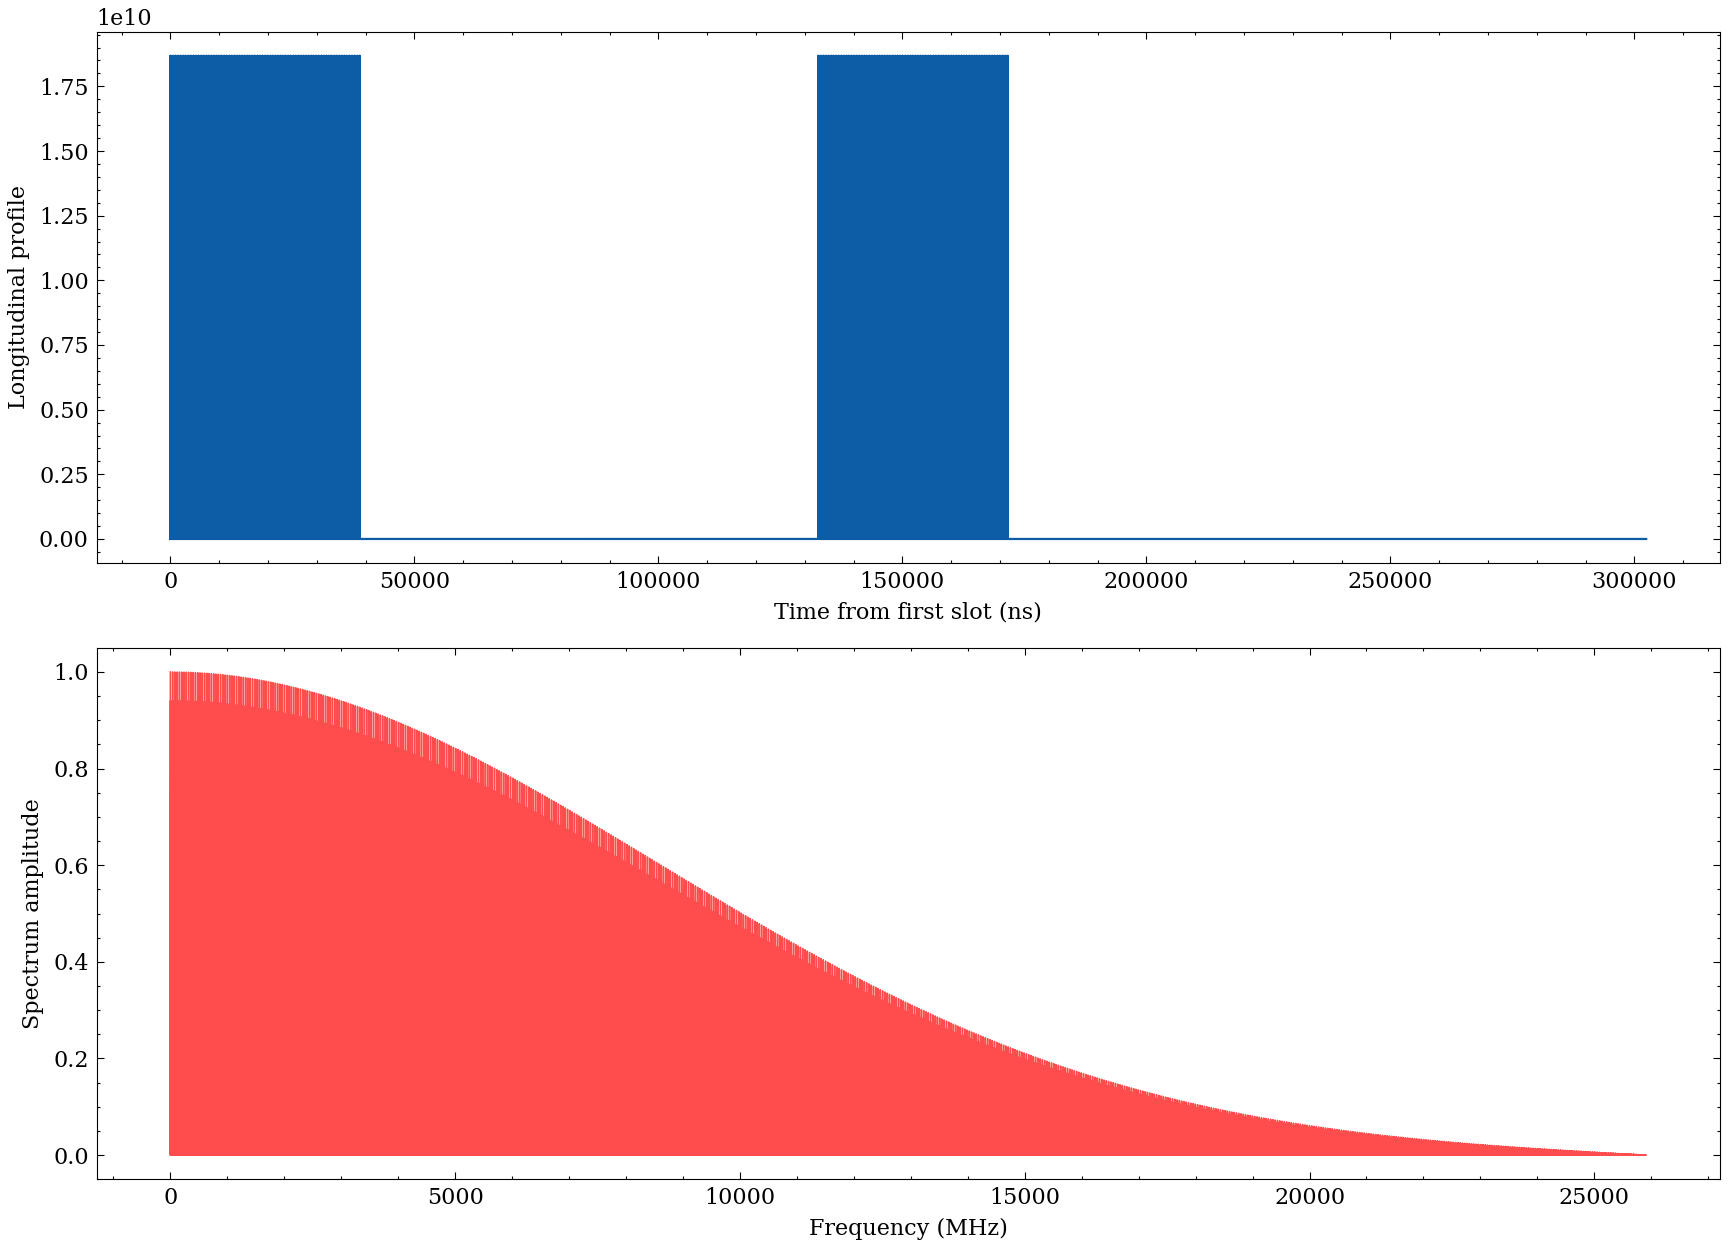

In [6]:
t, profile = beam.longitudinalProfile
f, amplitude = beam.spectrum

fig, axes = plt.subplots(2, 1, figsize=(11, 8))

# Plot the longitudinal profile
axes[0].plot((t - t[0]) * 1e9, profile)
axes[0].set(
    xlabel="Time from first slot (ns)",
    ylabel="Longitudinal profile",
)

# Plot the computed beam spectrum
axes[1].plot(f / 1e6, amplitude, lw=0.7, c="r", alpha=0.7)
axes[1].set(
    xlabel="Frequency (MHz)",
    ylabel="Spectrum amplitude",
)

plt.show()

## Single-beam power loss

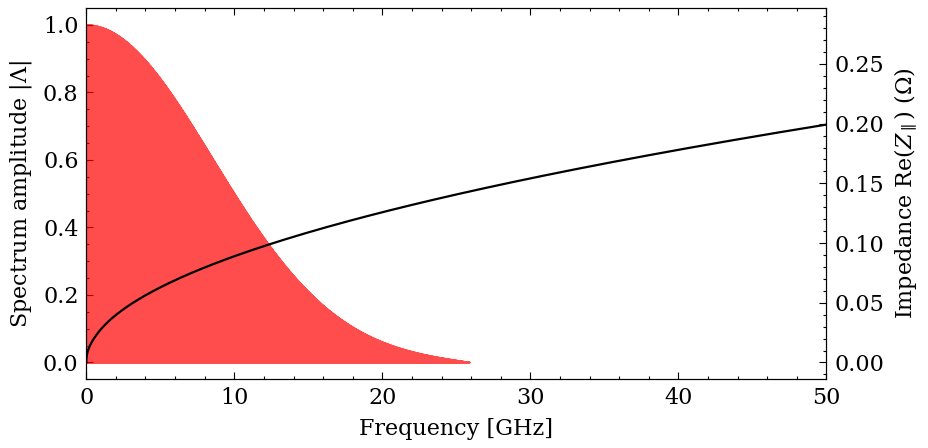

In [7]:
fig, ax = plt.subplots(1, 1, figsize=(6, 3))

# Plot the overlap of beam and impedance
ax.plot(f / 1e9, amplitude, c="r", lw=0.7, alpha=0.7)
ax.set(
    xlabel="Frequency [GHz]",
    ylabel=r"Spectrum amplitude $|\Lambda|$",
)

axx = ax.twinx()
axx.plot(Z.f / 1e9, Z.Zr, c="k")
axx.set(ylabel=r"Impedance $\operatorname{Re}(Z_\parallel)$ ($\Omega$)", xlim=[0, 50])

plt.show()

In [8]:
power_loss, power_density = beam.getPloss(Z)
print(f"   - {mode} single-beam power loss: {power_loss:.3f} W")

   - ZH single-beam power loss: 0.288 W


## Shifted power loss

A narrow impedance resonance may fall on a strong beam spectral line or between two lines. `getShiftedPloss` tests this sensitivity by moving the **whole impedance** rigidly in frequency while keeping the beam spectrum fixed. It does not shift the bunch arrival time.

The impedance is first interpolated on the beam FFT grid. Its spacing is

$$
\Delta f=f_{j+1}-f_j\approx f_\mathrm{rev}\approx3.3\ \mathrm{kHz}.
$$

The argument `shift=F` is the **half-width of the scan**, rather than its step. BIHC uses integer offsets $k=-n,\ldots,n-1$, where $n=\lfloor F/\Delta f\rfloor$, so each evaluated frequency offset is $k\Delta f$. For every offset, the cross correlation evaluates

$$
P(k)=\sum_j W_j\,\operatorname{Re}Z_\parallel(f_j-k\Delta f),
$$

where $W_j$ contains the beam-current and power-spectrum factors. Samples shifted outside the available frequency grid are set to zero. A positive offset moves impedance features to higher frequency.

Here $F=1/(2t_0)\approx20$ MHz. Scanning from approximately $-20$ to $+20$ MHz covers one complete slot-frequency interval, $1/t_0\approx40$ MHz, and tests all relative positions of a resonance within the dominant 25 ns spectral structure.

Revolution frequency / scan step: 3.307 kHz
Slot frequency: 40.079 MHz
Evaluated 12,120 offsets from -20.039 to 20.036 MHz
Minimum: 0.287 W at 20.036 MHz
Maximum: 0.289 W at -20.039 MHz


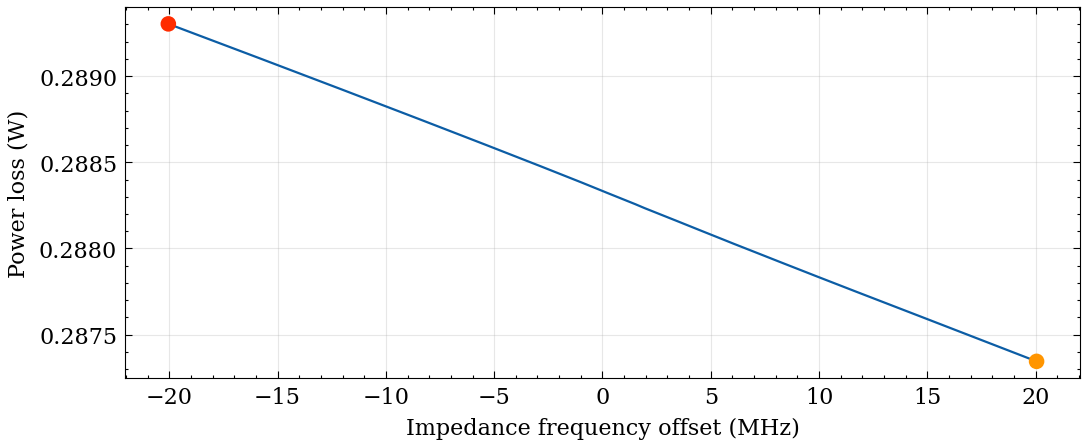

In [9]:
scan_half_width = 1 / (2 * beam.t0)
frequency_step = f[1] - f[0]
steps, shifted_power = beam.getShiftedPloss(Z, shift=scan_half_width)
frequency_offset_mhz = steps * frequency_step / 1e6
minimum = np.argmin(shifted_power)
maximum = np.argmax(shifted_power)

print(f"Revolution frequency / scan step: {frequency_step / 1e3:.3f} kHz")
print(f"Slot frequency: {1 / beam.t0 / 1e6:.3f} MHz")
print(
    f"Evaluated {len(steps):,} offsets from "
    f"{frequency_offset_mhz[0]:.3f} to {frequency_offset_mhz[-1]:.3f} MHz"
)
print(
    f"Minimum: {shifted_power[minimum]:.3f} W at "
    f"{frequency_offset_mhz[minimum]:.3f} MHz"
)
print(
    f"Maximum: {shifted_power[maximum]:.3f} W at "
    f"{frequency_offset_mhz[maximum]:.3f} MHz"
)

fig, ax = plt.subplots(figsize=(7, 3))
ax.plot(frequency_offset_mhz, shifted_power)
ax.scatter(
    frequency_offset_mhz[[minimum, maximum]],
    shifted_power[[minimum, maximum]],
    color=["C2", "C3"],
    zorder=3,
)
ax.set(xlabel="Impedance frequency offset (MHz)", ylabel="Power loss (W)")
ax.grid(alpha=0.3)
plt.show()

## Compare impedance and beam spectrum

The original impedance and its maximum-loss position show how a small resonance shift changes its overlap with the fixed beam spectral lines. The red curve gives the corresponding beam power weights and ends at the numerical FFT limit, while the full available impedance is shown through its maximum frequency. Individual revolution harmonics are more closely spaced than this plot can resolve.

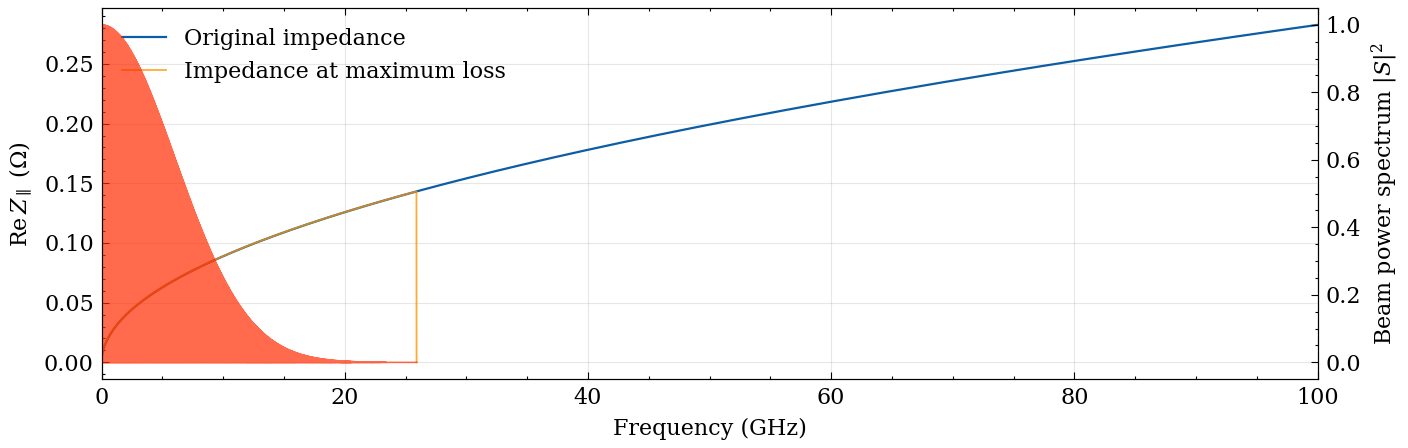

In [10]:
fig, ax = plt.subplots(figsize=(9, 3))

ax.plot(Z.f / 1e9, Z.Zr, color="C0", label="Original impedance")
ax.plot(
    beam.Zmax.f / 1e9,
    beam.Zmax.Zr,
    color="C2",
    alpha=0.8,
    lw=0.8,
    label="Impedance at maximum loss",
)
ax.set(
    xlabel="Frequency (GHz)",
    ylabel=r"$\mathrm{Re}\,Z_\parallel$ (Ω)",
)
ax.set_xlim(0, Z.f.max() / 1e9)
ax.legend(loc="upper left")

ax2 = ax.twinx()
ax2.plot(f / 1e9, beam.powerSpectrum[1], color="C3", alpha=0.7, lw=0.7)
ax2.set_ylabel(r"Beam power spectrum $|S|^2$")
ax.grid(alpha=0.3)
plt.show()